# Neutron Activation and Depletion of a Spherical Tokamak Model

## Notebook-3

This notebook finds out how the materials of a spherical tokamak become radioactive during operation, and how that activity dies away after shutdown. The model is the concentric-shell tokamak built in the base geometry notebook. In the centre there is a copper rod and a tungsten diboride (WB₂) protective shield. Around the plasma there is a tungsten first wall, a lead–lithium (PbLi) breeding blanket, a steel reflector and a tungsten outer shield. The machine runs for one full year at a neutron wall loading of 1 MW/m² (62.7 MW of fusion power, 2.2 × 10¹⁹ neutrons per second). It is then switched off and followed for 7 days.

OpenMC's depletion solver follows every component. The notebook gives (i) the tritium bred in the blanket, (ii) the decay heat of each component, and (iii) the most active isotopes at shutdown, after 1 day and after 7 days. The final inventories are saved in `depletion_results.h5`. They are the input to the SDDR notebook.

## Methodology

1. **Model and data.** The geometry, materials and D–T neutron source are read from `Spherical_tokamak_fendl_Basic_Configuration`. Neutron transport uses the FENDL-3.2 cross-section library set in `config.py`. The transmutation reactions and the radioactive decay data come from the depletion chain `chain_fendl30_fusion_complete.xml`.
2. **Depletable zones.** Each of the six solid components (copper rod, protective shield, first wall, breeding blanket, reflector, outer shield) is one depletable material with its exact analytic volume. Each component is therefore treated as one well-mixed zone.
3. **Neutron source rate.** The wall loading is turned into a fusion power and then into a neutron rate:
   $P_{fus} = \dfrac{NWL \times A}{14.1/17.6}$ and $S = \dfrac{P_{fus}}{17.6\ \mathrm{MeV}}$,
   where $A = 4\pi r^2$ is the area of the first-wall sphere ($r$ = 2 m, $A$ = 50.3 m²) and 14.1/17.6 is the share of the D–T energy carried by the neutron.
4. **Irradiation history.** A predictor integrator with three steps: 365 days with the source on, then 1 day and 6 days with the source off. This gives results at 0, 1 and 7 days after shutdown. With the source rate set to zero, only radioactive decay acts in the cooldown steps.
5. **Run choices.** The run is normalised to the source rate (neutrons per second). Photon transport is switched off, because depletion needs only neutron reaction rates. The chain is reduced to nuclides within five steps of the starting nuclides (`reduce_chain_level=5`) to save memory and time.
6. **Analysis.** The tritium inventory is checked against the breeding ratio from the transport notebook. The decay heat is plotted for each component. The most active isotopes are listed and plotted at shutdown, 1 day and 7 days. All tracked nuclides are exported, not only those with neutron cross sections, so that products such as W-185, W-187, Ta-182, Re-186 and Co-60 are kept for the SDDR notebook.

## Main settings

| Item | Value |
|---|---|
| Neutron wall loading | 1 MW/m² |
| Fusion power | 62.7 MW |
| Neutron source rate | 2.225 × 10¹⁹ n/s |
| Operating history | 365 d on, then 1 d and 6 d off |
| Neutron histories per transport step | 100 batches × 10,000 (raise to 100,000 per batch for final results) |
| Integrator | Predictor |

## Input data

* The base configuration folder (`materials.xml`, `geometry.xml`, `settings.xml`, `geometry_dimensions.csv`).
* The statepoint of the transport notebook (`..._TBR+FLUX+HEATING+DAMAGE/statepoint.100.h5`), used only for the tritium breeding ratio.
* The depletion chain file and the cross-section library set in the configuration.

## Outputs and main results

Files are saved in `Spherical_tokamak_fendl_Depletion+Activation`: `depletion_results.h5` and the statepoints, `tritium_breeding.png`, `all_components_decay_heat.png`, `all_components_top_isotopes_by_cooldown.csv` and `isotope_activity_stacked.png`.

What the results show (this run):

* **Tritium.** The blanket holds about 4.35 kg of tritium after one year (1.97 × 10¹⁰ Bq/cm³). The depletion solver gives 4.351 kg, and the value worked out from the breeding ratio of 1.277 is 4.36 kg. The two agree to about 0.3 %. Only about 0.25 % of the Li-6 is used up in a year, so a single 365-day step is acceptable.
* **First wall.** Most active component per unit volume. At shutdown W-185 is 2.6 × 10¹² Bq/cm³, W-181 is 1.5 × 10¹² and W-187 is 6.2 × 10¹¹. W-187 (half-life 24 h) halves in a day. After 7 days W-185 and W-181 are still high, and Re-186, Ta-182 and Re-184 are the main gamma emitters.
* **Blanket.** Tritium dominates the activity, but it is a pure beta emitter. Pb-203 (2.4 × 10⁹ Bq/cm³ at shutdown) and Pb-209 are the main gamma emitters.
* **Reflector.** Mn-56 (half-life 2.6 h) dominates at shutdown. After a day Cr-51 leads, and Fe-59 and Co-60 remain for longer.
* **Copper rod.** Cu-64 (12.7 h) dominates at shutdown. Co-60 (5.3 years) takes over after a few days.
* **Decay heat.** The protective shield and the first wall give the most, followed by the blanket and the reflector. At shutdown each is of the order of tens of kilowatts. This is well under 1 % of the 62.7 MW operating power, but it must still be removed.

## Modelling Assumptions and Limitations

* Each component is one depletion zone, so the activity is averaged over its thickness. The plasma-facing side of thick components (the 30 cm shield and the 100 cm blanket) is more active than the average, and the back is less active.
* The machine runs continuously at full power for one year. A real plant would run in pulses, for several years, with a lower availability.
* Only 1 day and 7 days of cooldown are followed. Long-lived products (for example Co-60, Ni-63 and Ta-182) matter for longer cooldown times and for waste classification.
* The tritium is not extracted, and no losses or burn-up in the plasma are modelled.
* The materials are pure. Real copper and steel contain impurities (for example Co, Nb, Ag) that change the long-term activity.
* **The chain file is checked here only by consistency tests (tritium against the breeding ratio, half-lives against decay). A comparison with an independent inventory code such as FISPACT-II would add confidence.**
* Run-to-run changes of a few per cent are seen for components behind thick shielding. Use higher particle counts for final results.

## References

1. P. K. Romano et al., "OpenMC: A state-of-the-art Monte Carlo code for research and development", *Annals of Nuclear Energy* 82 (2015) 90–97. https://doi.org/10.1016/j.anucene.2014.07.048
2. OpenMC user guide, depletion: https://docs.openmc.org/en/stable/usersguide/depletion.html
3. IAEA Nuclear Data Section, FENDL (Fusion Evaluated Nuclear Data Library): https://www-nds.iaea.org/fendl/

In [2]:
import openmc
import openmc.deplete

import matplotlib.pyplot as plt
import os
import math

import numpy as np
import pandas as pd

from config import data_library, prefix, MODEL_NAME, BASE_DIR



In [3]:
print(MODEL_NAME)
print(BASE_DIR)

DEPLETION_DIR = f"./{MODEL_NAME}_Depletion+Activation"
os.makedirs(DEPLETION_DIR, exist_ok=True)

print(DEPLETION_DIR)

Spherical_tokamak_fendl
./Spherical_tokamak_fendl_Basic_Configuration
./Spherical_tokamak_fendl_Depletion+Activation


In [4]:
depletion_chain = "/workspace/chain/chain_fendl30_fusion_complete.xml"

if os.path.exists(depletion_chain):
    print("Chain file exists")
    print(f"Path to chain file: {depletion_chain}")
    openmc.config['chain_file'] = depletion_chain
else:
    print("Chain file not found.")

Chain file exists
Path to chain file: /workspace/chain/chain_fendl30_fusion_complete.xml


In [4]:
# Clear OpenMC's memory of old IDs before loading new ones
openmc.reset_auto_ids()

# Apply the global library
openmc.config['cross_sections'] = data_library

# Loading materials FIRST from the base directory
original_mats_path = os.path.join(BASE_DIR, 'materials.xml')
materials = openmc.Materials.from_xml(original_mats_path)

# Passing the loaded materials directly into the geometry parser
geometry = openmc.Geometry.from_xml(
    os.path.join(BASE_DIR, 'geometry.xml'), 
    materials=materials
)

# Loading settings 
settings = openmc.Settings.from_xml(os.path.join(BASE_DIR, 'settings.xml'))



# Overwrite the simulation parameters
settings.run_mode = "fixed source"
settings.batches = 100                                            #100
settings.particles = 10000                                 #1_00_000
settings.inactive = 20

# Disable photon transport: the depletion solver only requires neutron tracks, so turning this off to save computational time and memory
settings.photon_transport = False

In [5]:
# Re-link the Python variables to the loaded cells
all_cells = geometry.get_all_cells()


for cell_id, c in all_cells.items():
    print(f"ID: {cell_id} | Name: '{c.name}'")


ID: 1 | Name: 'Copper Magnet Rod'
ID: 2 | Name: 'Protective Shield'
ID: 3 | Name: 'First Wall'
ID: 4 | Name: 'Breeding Blanket'
ID: 5 | Name: 'Reflector'
ID: 6 | Name: 'Outer Shield'
ID: 7 | Name: 'Plasma'
ID: 8 | Name: 'Vacuum Space'
ID: 9 | Name: 'Graveyard Void'


In [6]:
# Re-link the Python variables to the loaded cells using exact names
cell_cu = next(c for c in all_cells.values() if c.name == 'Copper Magnet Rod')
cell_shield = next(c for c in all_cells.values() if c.name == 'Protective Shield')
cell_fw = next(c for c in all_cells.values() if c.name == 'First Wall')
cell_blanket = next(c for c in all_cells.values() if c.name == 'Breeding Blanket')
cell_mirror = next(c for c in all_cells.values() if c.name == 'Reflector')
cell_outer = next(c for c in all_cells.values() if c.name == 'Outer Shield')

cell_plasma = next(c for c in all_cells.values() if c.name == 'Plasma') #not used
cell_vac = next(c for c in all_cells.values() if c.name == 'Vacuum Space') #not used


In [7]:
geom_df = pd.read_csv(os.path.join(BASE_DIR, 'geometry_dimensions.csv'), index_col="Component")

def dim(name, col):
    return float(geom_df.loc[name, col])

# Radii (cm)
r_cu_in       = dim("Copper Magnet Rod (Central)",  "Inner Radius (cm)")
r_cu_out      = dim("Copper Magnet Rod (Central)",  "Outer Radius (cm)")
r_shield_in   = dim("Protective Shield (Central)",  "Inner Radius (cm)")
r_shield_out  = dim("Protective Shield (Central)",  "Outer Radius (cm)")
r_fw_in       = dim("First Wall (Spherical)",       "Inner Radius (cm)")
r_fw_out      = dim("First Wall (Spherical)",       "Outer Radius (cm)")
r_blanket_in  = dim("Breeding Blanket (Spherical)", "Inner Radius (cm)")
r_blanket_out = dim("Breeding Blanket (Spherical)", "Outer Radius (cm)")
r_mirror_in   = dim("Steel Reflector (Spherical)",  "Inner Radius (cm)")
r_mirror_out  = dim("Steel Reflector (Spherical)",  "Outer Radius (cm)")
r_outer_in    = dim("Outer Shield (Spherical)",     "Inner Radius (cm)")
r_outer_out   = dim("Outer Shield (Spherical)",     "Outer Radius (cm)")

# The central column (Cu rod + shield) is capped by the outermost sphere,
# so its half-length equals that radius
z_bound = r_outer_out

# The spherical shells must touch each other
assert np.isclose(r_fw_out, r_blanket_in) and np.isclose(r_blanket_out, r_mirror_in) \
   and np.isclose(r_mirror_out, r_outer_in), "shell radii not contiguous - check geometry_dimensions.csv"

# Analytic volumes (cm^3)
vol_cu      = dim("Copper Magnet Rod (Central)",  "Volume (cm^3)")
vol_shield  = dim("Protective Shield (Central)",  "Volume (cm^3)")
vol_fw      = dim("First Wall (Spherical)",       "Volume (cm^3)")
vol_blanket = dim("Breeding Blanket (Spherical)", "Volume (cm^3)")
vol_mirror  = dim("Steel Reflector (Spherical)",  "Volume (cm^3)")
vol_outer   = dim("Outer Shield (Spherical)",     "Volume (cm^3)")

print(geom_df[['Inner Radius (cm)', 'Outer Radius (cm)', 'Volume (cm^3)']])
print(f"Column half-length z_bound = {z_bound} cm")

                             Inner Radius (cm)        Outer Radius (cm)  \
Component                                                                 
Copper Magnet Rod (Central)                0.0                     20.0   
Protective Shield (Central)               23.0                     53.0   
First Wall (Spherical)                   200.0                    201.0   
Breeding Blanket (Spherical)             201.0                    301.0   
Steel Reflector (Spherical)              301.0                    321.0   
Outer Shield (Spherical)                 321.0                    351.0   
Plasma Torus                    Major a: 126.5  Minor b: 100.0, c: 50.0   

                              Volume (cm^3)  
Component                                    
Copper Magnet Rod (Central)    8.814428e+05  
Protective Shield (Central)    4.994114e+06  
First Wall (Spherical)         4.872032e+05  
Breeding Blanket (Spherical)   7.843064e+07  
Steel Reflector (Spherical)    2.396142e+07  
Ou

# Re-assigning Volumes and Depletable Flags via Cells

Depletion needs the volume of every depletable material to turn atom densities into numbers of atoms. Each component is given its analytic volume from `geometry_dimensions.csv` and is marked as depletable. The six components then become six separate depletion zones.

In [8]:
# Components table (same component names as in the SDDR notebook): the cell and its analytic volume
components = {
    'Copper Magnet Rod': dict(cell=cell_cu,      vol=vol_cu),
    'Protective Shield': dict(cell=cell_shield,  vol=vol_shield),
    'First Wall':        dict(cell=cell_fw,      vol=vol_fw),
    'Breeding Blanket':  dict(cell=cell_blanket, vol=vol_blanket),
    'Reflector':         dict(cell=cell_mirror,  vol=vol_mirror),
    'Outer Shield':      dict(cell=cell_outer,   vol=vol_outer),
}

# Assign the analytic volume and mark every component material as depletable
for comp in components.values():
    comp['cell'].fill.volume = comp['vol']
    comp['cell'].fill.depletable = True

# Extract the updated materials list from the geometry
materials = openmc.Materials(geometry.get_all_materials().values())

# Verify it worked
depletable_mats = [m.name for m in materials if m.depletable]
print(f"Depletable materials set: {depletable_mats}")

if not depletable_mats:
    raise RuntimeError("Materials not depleting. Check if the cells are filled with valid materials.")

Depletable materials set: ['Central Pole (Cu)', 'Tungsten diboride (WB2)', 'First Wall (W)', 'Breeding Blanket (PbLi)', 'Steel Reflector', 'Outer Shield (W)']


# Build Model and Depletion Operator

The operator joins the OpenMC model with the depletion chain. The run is normalised to the source rate (neutrons per second). `reduce_chain_level=5` keeps only nuclides within five reaction or decay steps of the starting nuclides, which shortens the run and saves memory. Photon transport is switched off in the settings, because only neutron reaction rates are needed here.

In [9]:
model = openmc.Model(geometry=geometry, materials=materials, settings=settings)

operator = openmc.deplete.CoupledOperator(
    model, 
    depletion_chain,
    #reduce_chain=True, ---------------> removed for openmc 0.16.0
    reduce_chain_level=5,
    #Pruning the depletion matrix to save RAM and speed up the solver. 
    #Level 5 retains all relevant transmutations/decays (up to 5 steps from the initial isotopes) 
    #without altering the final decay heat or tritium mass results.
    normalization_mode="source-rate"
)
print("Depletion operator geenrated successfully.")

Depletion operator geenrated successfully.


# Operational Period

The plasma is on for 365 days (step 1) and then off for 1 day (step 2) and for 6 more days (step 3). The results at the end of the steps are therefore at shutdown, 1 day and 7 days after shutdown.

The neutron source rate comes from the target wall loading of 1 MW/m² on the first-wall sphere: $P_{fus} = NWL \times A / (14.1/17.6)$ and $S = P_{fus} / (17.6\ \mathrm{MeV})$. This is the same normalisation as in the transport notebook. The source rate is set to zero in the cooldown steps, so only radioactive decay acts.

In [10]:
days = 24 * 60 * 60

timesteps = [
    365 * days,  # Step 1: Plasma ON for 1 Year
    1 * days,    # Step 2: Plasma OFF (Cooldown Day 1)
    6 * days     # Step 3: Plasma OFF (Cooldown Day 7)
]

#----- Source from a target neutron wall loading (same as in TBR notebook)------###
target_nwl_MW_m2 = 1.0                          
r_fw_inner_m = r_fw_in / 100.0                    
fw_area_m2 = 4.0 * math.pi * r_fw_inner_m**2    
neutron_fraction = 14.1 / 17.6                  

fusion_power_watts = target_nwl_MW_m2 * 1e6 * fw_area_m2 / neutron_fraction   
joules_per_dt_reaction = 17.6e6 * 1.60217663e-19
source_strength = fusion_power_watts / joules_per_dt_reaction                 
print(f"Fusion power {fusion_power_watts/1e6:.1f} MW -> S = {source_strength:.3e} n/s "
      f"(wall loading {target_nwl_MW_m2} MW/m2 on {fw_area_m2:.1f} m2)")

source_rates = [source_strength] + [0.0] * (len(timesteps) - 1)     # plasma ON in step 1, OFF afterwards

Fusion power 62.7 MW -> S = 2.225e+19 n/s (wall loading 1.0 MW/m2 on 50.3 m2)


# Run the Integrator

The predictor integrator runs one neutron transport calculation per step to find the reaction rates, and then solves the depletion equations for all components. The results are written to `depletion_results.h5` in the depletion folder. This is the longest part of the notebook.

In [12]:
integrator = openmc.deplete.PredictorIntegrator(
    operator, 
    timesteps, 
    source_rates=source_rates
)

# Save the original directory path
original_dir = os.getcwd()

try:
    os.chdir(DEPLETION_DIR)
    integrator.integrate()
    
finally:
    #Always return to the original notebook directory, even on a crash
    os.chdir(original_dir)

print(f"\nActivation complete. 'depletion_results.h5' and all statepoints are saved in '{DEPLETION_DIR}'.")

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/usr/local/lib/python3.12/dist-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


[openmc.deplete] t=31622400.0 s, dt=518400 s, source=0.0
 Creating state point openmc_simulation_n2.h5...
[openmc.deplete] t=32140800.0 (final operator evaluation)
 Creating state point openmc_simulation_n3.h5...

Activation complete. 'depletion_results.h5' and all statepoints are saved in './Spherical_tokamak_fendl_Depletion+Activation'.


# `Activation & Depletion Results Analysis`

This section reads `depletion_results.h5` and gives three results: the tritium bred in the blanket, the decay heat of each component, and the most active isotopes at shutdown, after 1 day and after 7 days.

# Loading Results

The results file is opened, and the list of all tracked nuclides (`nuc_all`) is stored. This list is reused when the materials are exported at each time step.

In [11]:
results_path = os.path.join(DEPLETION_DIR, 'depletion_results.h5')
results = openmc.deplete.Results(results_path)

nuc_all = list(results[0].index_nuc)        # all nuclides tracked by the depletion (reused in cell 24)

blanket_id = str(components['Breeding Blanket']['cell'].fill.id)

# Graph: Tritium in the Breeding Blanket

Tritium in the PbLi comes mainly from ⁶Li(n,t)⁴He, with a smaller share from ⁷Li(n,n′t)⁴He. Two results are drawn:

* **Blue curve:** calculated from the tritium breeding ratio of the transport run (the `H3-production` tally). While the plasma is on, tritium is bred at TBR × S atoms per second and decays with a half-life of 12.32 years: $N(t) = TBR\,S\,(1 - e^{-\lambda t})/\lambda$. After shutdown only the decay remains, which is very slow (about 0.1 % per week).
* **Red points:** the tritium mass found by the depletion solver at the end of each step.

The two agree: 4.36 kg from the breeding ratio and 4.351 kg from the solver. They are found by two different routes (a tally and the reaction rates of the chain), so the agreement is a useful check that the chain contains the Li-6(n,t) reaction and the tritium decay. Extraction, losses and burn-up in the plasma are not modelled, so this is the tritium held in the blanket for one year without extraction.

> **Note:** the legend of the red curve in the code cell below still reads "no Li-6(n,t) in chain". This text is left over from an older chain, which had no Li-6(n,t) reaction. It is no longer true, as the result above shows.

TBR from the transport run = 1.2772


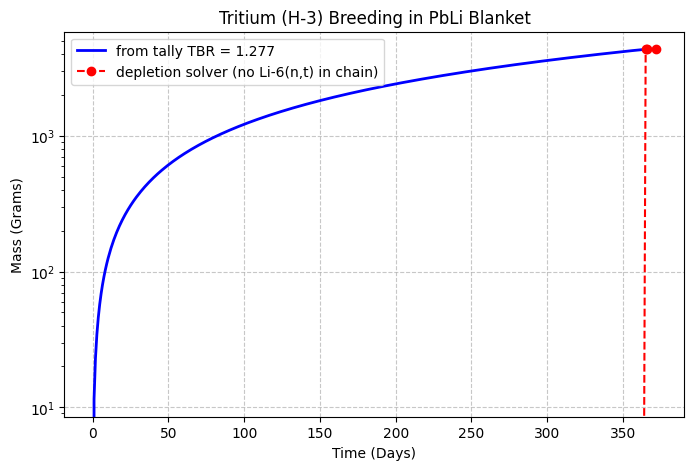

Tritium at end of irradiation: 4.36 kg (from TBR)
Tritium in the depletion solver: 4.351e+00 kg


In [12]:
# TBR taken from the TBR notebook's statepoint (no new file needed)
tbr_sp_path = f"./{MODEL_NAME}_TBR+FLUX+HEATING+DAMAGE/statepoint.100.h5"
with openmc.StatePoint(tbr_sp_path) as sp_tbr:
    TBR = float(sp_tbr.get_tally(name='TBR').mean.sum())

print(f"TBR from the transport run = {TBR:.4f}")

T_HALF_S = 12.32 * 365.25 * days            # tritium half-life [s]
lam = np.log(2) / T_HALF_S
M_T = 3.01604928                                 # g/mol
N_A = 6.02214076e23
t_irr = timesteps[0]                             # irradiation time = first time step (365 d)

P = TBR * source_strength                     # tritons bred per second while the plasma is ON

def tritium_atoms(t_s):
    t_s = np.asarray(t_s, dtype=float)
    n_end = P * (1 - np.exp(-lam * t_irr)) / lam                      # inventory at shutdown
    return np.where(t_s <= t_irr, P * (1 - np.exp(-lam * t_s)) / lam,  # build-up with decay
                    n_end * np.exp(-lam * (t_s - t_irr)))              # decay after shutdown

t_dense = np.linspace(0, sum(timesteps), 400)
h3_mass_g = tritium_atoms(t_dense) * M_T / N_A

# tritium mass seen by the depletion solver (only for comparison)
t_sec, h3_depl = results.get_mass(blanket_id, "H3")

plt.figure(figsize=(8, 5))
plt.plot(t_dense / days, h3_mass_g, color='blue', linewidth=2, label=f'from tally TBR = {TBR:.3f}')
plt.plot(t_sec / days, h3_depl, 'o--', color='red', label='depletion solver (no Li-6(n,t) in chain)')
plt.yscale('log')
plt.title("Tritium (H-3) Breeding in PbLi Blanket")
plt.xlabel("Time (Days)")
plt.ylabel("Mass (Grams)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.savefig(os.path.join(DEPLETION_DIR, 'tritium_breeding.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Tritium at end of irradiation: {tritium_atoms([t_irr])[0] * M_T / N_A / 1000:.2f} kg (from TBR)")
print(f"Tritium in the depletion solver: {h3_depl[1] / 1000:.3e} kg")

# Graph: Component Decay Heat (Cooldown Curves)

When the plasma stops, the heating in the structure comes only from the decay of the activated nuclides. The plot shows this for each component on a logarithmic scale.

* **Size of the heat.** At shutdown the protective shield gives the most decay heat (a large volume of tungsten), followed by the first wall. The blanket and the reflector are somewhat lower. Each of these four is of the order of tens of kilowatts. The outer shield and the copper rod give about a kilowatt or less. The total is well under 1 % of the 62.7 MW operating power, but cooling is still needed after shutdown.
* **Speed of the fall.** The heat drops fast in the first day, as short-lived nuclides decay (W-187, Mn-56, Cu-64, Pb-209). After that, W-185, W-181 and Co-60 leave a slow tail.
* **Copper rod.** In this model the central rod is ordinary (resistive) copper, so a quench is not an issue. Its decay heat is only a few watts after 7 days. If superconducting coils were used instead, even small heat loads would matter for the cryogenic plant.

**How to read the plot.** Only four points are calculated for each component (0, 365, 366 and 372 days). The values at day 0 are the fresh, inactive materials (almost zero), and the straight lines up to day 365 only join these two points on a logarithmic axis. They do not show the build-up. Only the part after day 365 is a cooldown curve.

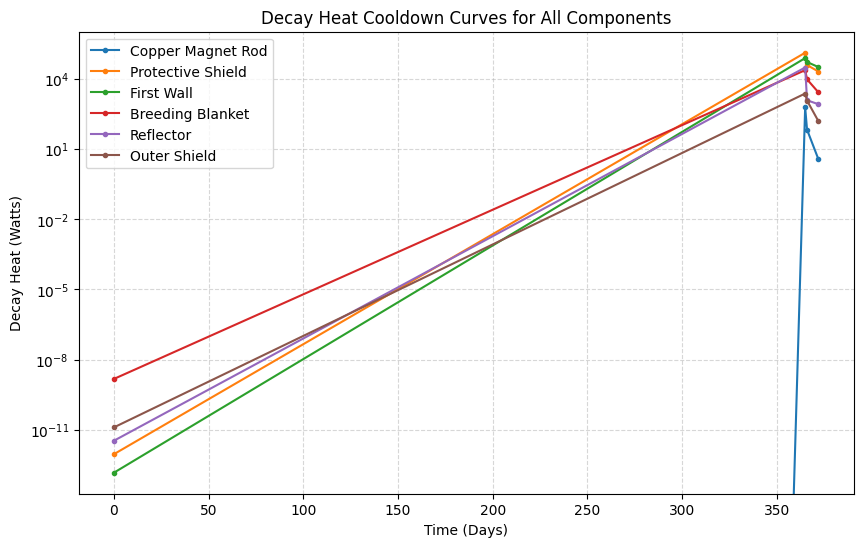

In [13]:
plt.figure(figsize=(10, 6))

for name, comp in components.items():
    # Extract data
    t_sec, heat = results.get_decay_heat(str(comp['cell'].fill.id))
    # Convert seconds to days for a clean x-axis
    t_days = t_sec / days
    # Plot each component
    plt.semilogy(t_days, heat, marker='.', label=name)

plt.title("Decay Heat Cooldown Curves for All Components")
plt.xlabel("Time (Days)")
plt.ylabel("Decay Heat (Watts)")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(os.path.join(DEPLETION_DIR, 'all_components_decay_heat.png'), dpi=300, bbox_inches='tight')
plt.show()

# Top Radioactive Isotopes (Shutdown, 1 Day, 7 Days)

The table lists the seven isotopes with the highest activity (Bq/cm³) in every component at 0 d (the moment the plasma stops), at 1 d and at 7 d. The stacked chart after it shows the same data on a logarithmic scale.

The materials are exported with `nuc_with_data` set to **all** nuclides tracked by the depletion. By default `Results.export_to_materials()` removes every nuclide that has no neutron cross section in the transport library (FENDL-3.2). That would remove many of the activation products that matter for dose, such as W-185, W-187, Ta-182, Re-186, Mn-54, Co-60 and Fe-55. The same full inventory is used as the photon source in the SDDR notebook.

How to read the table:

* High activity is not the same as high dose. W-185, Fe-55 and H-3 emit almost no gamma rays, so they matter little for the dose.
* Be-8, Li-8 and He-6 are in the table at 0 d only because they are still being made while neutrons are present. Their half-lives are far less than a second, so they are gone within seconds of shutdown. They can be ignored.
* A name such as `W183_m1` or `Tc99_m1` is a metastable (excited) state of the nuclide.

In [14]:
# Number of top radioactive isotopes to extract per component
num_isotopes = 7

# results index: 1 = end of irradiation, 2 = after cooldown day 1, 3 = after cooldown day 7
steps = {1: '0 d (shutdown)', 2: '1 d', 3: '7 d'}

all_data = []
for step, label in steps.items():
    # Clear OpenMC's internal memory to prevent ID overlap warnings
    openmc.reset_auto_ids()

    # nuc_with_data=nuc_all keeps the nuclides that have no neutron cross sections in FENDL
    mats_at_step = results.export_to_materials(step, nuc_with_data=nuc_all, path=original_mats_path)

    for name, comp in components.items():
        comp_mat = next((m for m in mats_at_step if str(m.id) == str(comp['cell'].fill.id)), None)
        if not comp_mat:
            continue

        activities = comp_mat.get_activity(by_nuclide=True)          # Bq/cm3

        sorted_acts = sorted([(nuc, act) for nuc, act in activities.items() if act > 0],
                             key=lambda x: x[1], reverse=True)[:num_isotopes]

        for nuc, act in sorted_acts:
            all_data.append({"Cooldown": label, "Component": name, "Isotope": nuc, "Activity (Bq/cm3)": act})

df_all = pd.DataFrame(all_data)

csv_path = os.path.join(DEPLETION_DIR, 'all_components_top_isotopes_by_cooldown.csv')
df_all.to_csv(csv_path, index=False)

df_all["Activity (Bq/cm3)"] = df_all["Activity (Bq/cm3)"].apply(lambda x: f"{x:.3e}")
print(f"\nFiles saved to: {DEPLETION_DIR}")
print(f"\n Top {num_isotopes} Radioactive Isotopes per Component (shutdown, 1 d, 7 d)")
print(df_all.to_string(index=False))


Files saved to: ./Spherical_tokamak_fendl_Depletion+Activation

 Top 7 Radioactive Isotopes per Component (shutdown, 1 d, 7 d)
      Cooldown         Component  Isotope Activity (Bq/cm3)
0 d (shutdown) Copper Magnet Rod     Cu64         5.291e+09
0 d (shutdown) Copper Magnet Rod     Cu66         1.214e+09
0 d (shutdown) Copper Magnet Rod     Cu62         4.915e+08
0 d (shutdown) Copper Magnet Rod     Ni65         1.904e+07
0 d (shutdown) Copper Magnet Rod     Co60         9.783e+06
0 d (shutdown) Copper Magnet Rod     Co62         5.888e+06
0 d (shutdown) Copper Magnet Rod     Ni63         1.439e+06
0 d (shutdown) Protective Shield     W185         1.726e+11
0 d (shutdown) Protective Shield     W181         7.914e+10
0 d (shutdown) Protective Shield     W187         5.763e+10
0 d (shutdown) Protective Shield      Be8         1.709e+10
0 d (shutdown) Protective Shield  W183_m1         1.192e+10
0 d (shutdown) Protective Shield  W185_m1         8.799e+09
0 d (shutdown) Protective Shield

## Activity of the Top Isotopes (Stacked Chart)

One panel for each component. The bars show the activity of the top isotopes at 0 d, 1 d and 7 d, stacked and on a logarithmic scale. Short-lived isotopes disappear from the bars after the first day, and the long-lived ones (for example W-185, W-181, Co-60 and H-3) remain.

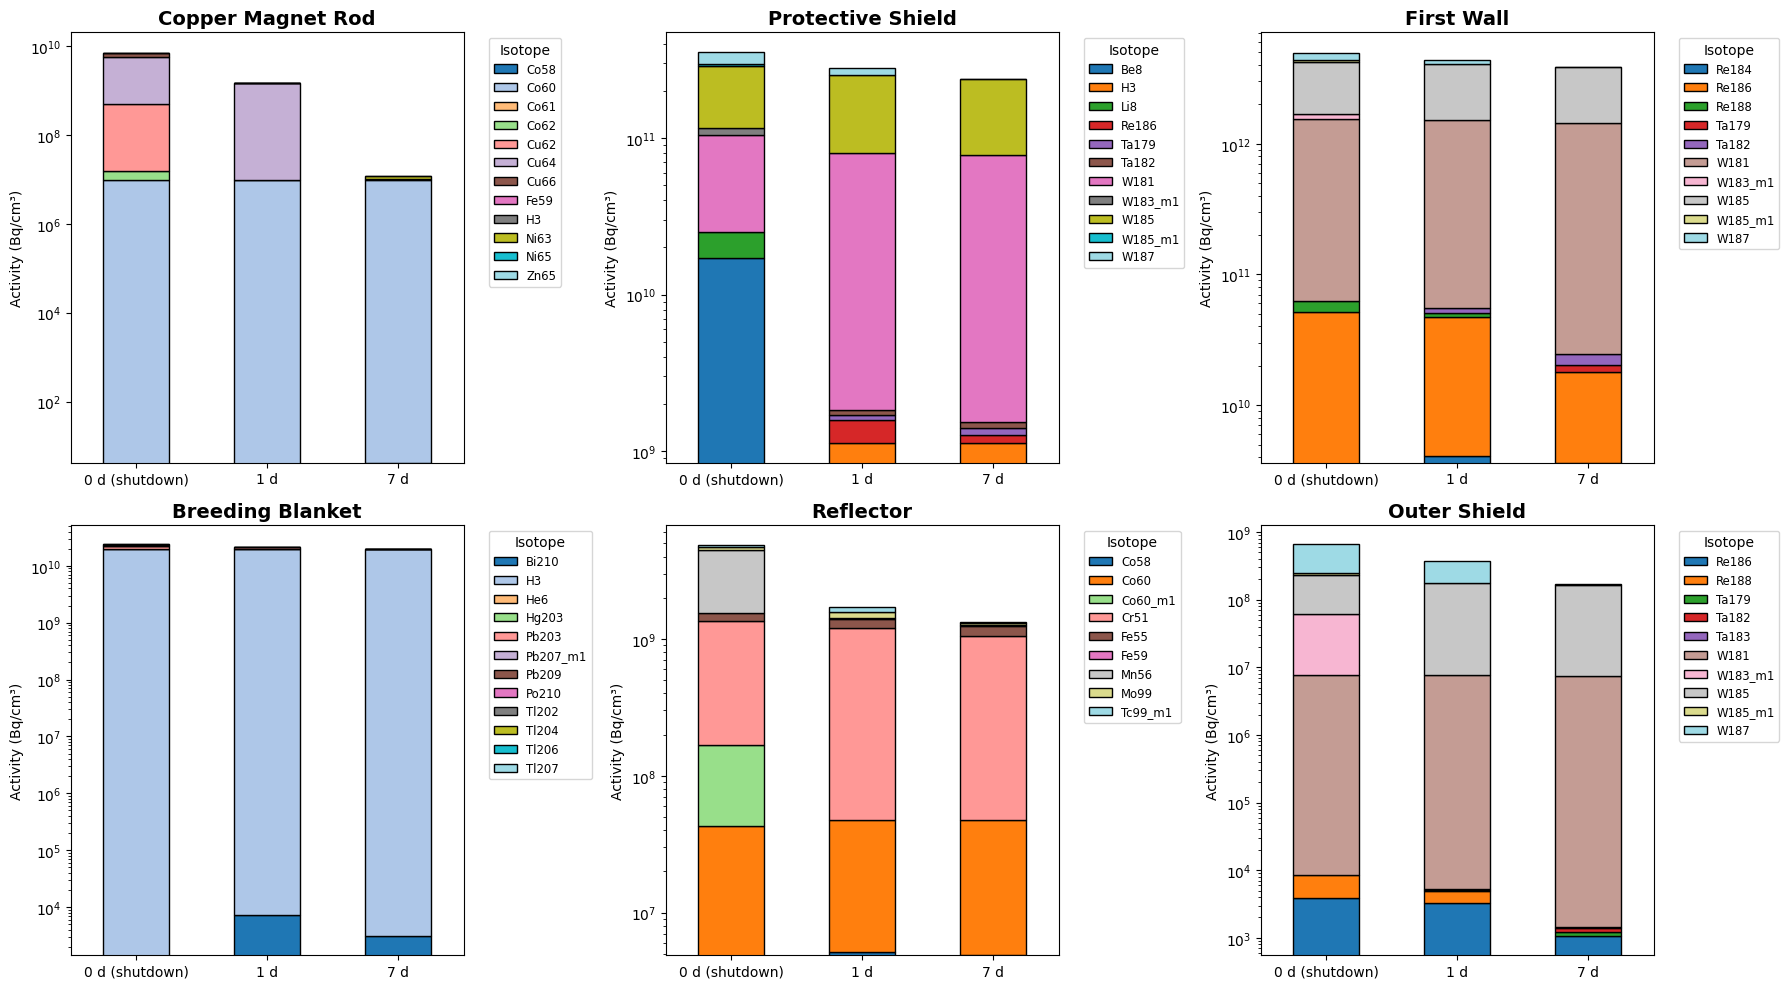

In [15]:
df_plot = pd.DataFrame(all_data)

comp_names = list(components)       # same order as the components table

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, name in enumerate(comp_names):
    df_comp = df_plot[df_plot['Component'] == name]
    df_pivot = df_comp.pivot(index="Cooldown", columns="Isotope", values="Activity (Bq/cm3)").fillna(0)
    df_pivot = df_pivot.reindex(['0 d (shutdown)', '1 d', '7 d'])

    #plotting stacked bar
    df_pivot.plot(kind='bar', stacked=True, ax=axes[i], colormap='tab20', edgecolor='black')
    axes[i].set_title(name, fontsize=14, fontweight='bold')
    axes[i].set_yscale('log')
    axes[i].set_ylabel('Activity (Bq/cm³)')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(title='Isotope', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')

plt.tight_layout()
stacked_path = os.path.join(DEPLETION_DIR, 'isotope_activity_stacked.png')
plt.savefig(stacked_path, dpi=300, bbox_inches='tight')
plt.show()
